# Análise dos experimentos

Lê `scripts/experiments/*/{runs,timeline,probe,summary}.csv` produzidos por
`scripts/experiment.py` e mostra tabelas e gráficos.

Pré-requisitos: `pip install pandas matplotlib jupyter`, e pelo menos um cenário
já executado (`scripts/experiment.py baseline --seeds 5`).

Execute as células em ordem. O DataFrame `runs` agrega todas as execuções;
`ttr` agrega os resumos de falha. Ajuste `SCENARIO` na última célula para
inspecionar outro diretório em `scripts/experiments/`.


In [24]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    display = print

root = Path.cwd()
while not (root / "compose.yaml").exists() and root != root.parent:
    root = root.parent
EXP = root / "scripts" / "experiments"

frames = []
for f in sorted(EXP.glob("*/runs.csv")):
    df = pd.read_csv(f)
    if df.empty:
        continue
    df["experiment"] = f.parent.name
    frames.append(df)
runs = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()

print(f"{len(runs)} runs from {runs['experiment'].nunique() if not runs.empty else 0} experiments")
runs.head()


200 runs from 14 experiments


,tag,nodes,clients,ops,seed,duration_s,throughput_ops_s,p50_ms,p95_ms,p99_ms,retry_pct,attempts_per_op,attempts_p99,wrong_leader_pct,linearizable,experiment
0,baseline,3,8,1600,1,0.915,1747.90,4.320,6.889,8.309,0.0,1.0,1.0,0.0,ok,baseline
1,baseline,3,8,1600,2,1.004,1594.33,4.499,8.016,17.582,0.0,1.0,1.0,0.0,ok,baseline
2,baseline,3,8,1600,3,0.960,1667.35,4.520,7.005,9.280,0.0,1.0,1.0,0.0,ok,baseline
3,baseline,3,8,1600,4,0.949,1686.63,4.400,6.686,9.899,0.0,1.0,1.0,0.0,ok,baseline
4,baseline,3,8,1600,5,0.961,1664.52,4.509,6.871,8.999,0.0,1.0,1.0,0.0,ok,baseline


In [25]:
METRICS = ["throughput_ops_s", "p50_ms", "p95_ms", "p99_ms", "retry_pct", "attempts_per_op"]

if runs.empty:
    print("no experiments yet: run scripts/experiment.py first")
else:
    table = runs.groupby(["experiment", "tag"])[METRICS].agg(["mean", "std"]).round(2)
    display(table)


throughput_ops_s          p50_ms        \
                                            mean     std    mean   std   
experiment     tag                                                       
baseline       baseline                  1667.68   49.64    4.46  0.07   
kill-leader-n3 kill-after                1652.75   75.45    4.55  0.24   
               kill-during               1797.86  109.16    4.13  0.07   
kill-leader-n5 kill-after                1325.62  156.45    5.74  0.65   
               kill-during               1454.15   98.39    5.20  0.40   
kill-leader-n7 kill-after                1029.19  149.15    7.37  1.02   
               kill-during               1107.95  151.52    6.73  0.80   
netem-d100ms   netem-100ms-0%              25.93    0.07  301.83  0.06   
netem-d50ms    netem-50ms-0%               50.43    1.70  152.70  1.63   
netem-l2pct    netem-0ms-2%               594.23  106.25    1.98  0.31   
netem-l5pct    netem-0ms-5%               238.34   54.48    1.83  0.14   
partition-n3   partition-after           1710.13   64.05    4.38  0.11   
               partition-during          1753.68  129.95    4.20  0.08   
partition-n5   partition-after           1280.37   98.79    5.90  0.51   
               partition-during          1412.02  114.13    5.27  0.48   
partition-n7   partition-after            940.61   95.66    8.00  0.67   
               partition-during          1011.38   72.54    7.41  0.51   
sweep-n3       n3                        1685.72   96.58    4.48  0.27   
sweep-n5       n5                        1207.19   83.68    5.99  0.23   
sweep-n7       n7                         949.45   72.95    7.87  0.56   

                                 p95_ms         p99_ms         retry_pct  \
                                   mean    std    mean     std      mean   
experiment     tag                                                         
baseline       baseline            7.11   0.38   11.38    5.11      0.00   
kill-leader-n3 kill-after          7.27   0.36    9.72    2.13      0.30   
               kill-during         6.44   0.22    9.10    3.34      0.20   
kill-leader-n5 kill-after          9.18   1.19   12.51    4.55      0.35   
               kill-during         8.17   0.56   12.17    4.33      0.30   
kill-leader-n7 kill-after         12.10   1.70   18.10    5.29      0.35   
               kill-during        11.02   1.60   16.62    8.36      0.35   
netem-d100ms   netem-100ms-0%    304.38   0.83  312.99    3.58      0.50   
netem-d50ms    netem-50ms-0%     175.19  23.60  204.26   47.59      0.00   
netem-l2pct    netem-0ms-2%        4.91   0.86  210.17    1.03      0.50   
netem-l5pct    netem-0ms-5%      200.06  22.59  487.18  292.51      0.49   
partition-n3   partition-after     6.96   0.36   10.40    4.09      0.40   
               partition-during    6.63   0.39    9.74    3.77      0.35   
partition-n5   partition-after     9.47   0.71   12.49    2.23      0.35   
               partition-during    8.45   0.82   11.60    2.94      0.40   
partition-n7   partition-after    13.20   1.22   18.49    5.33      0.45   
               partition-during   12.44   0.84   17.39    3.87      0.45   
sweep-n3       n3                  7.10   0.43   10.18    2.58      0.50   
sweep-n5       n5                 10.36   1.55   15.54    7.42      0.50   
sweep-n7       n7                 13.24   1.38   18.28    4.23      0.50   

                                      attempts_per_op        
                                  std            mean   std  
experiment     tag                                           
baseline       baseline          0.00            1.00  0.00  
kill-leader-n3 kill-after        0.26            1.00  0.00  
               kill-during       0.26            1.00  0.00  
kill-leader-n5 kill-after        0.24            1.01  0.01  
               kill-during       0.26            1.01  0.01  
kill-leader-n7 kill-after        0.24            1.01  0.01  
               kill-du

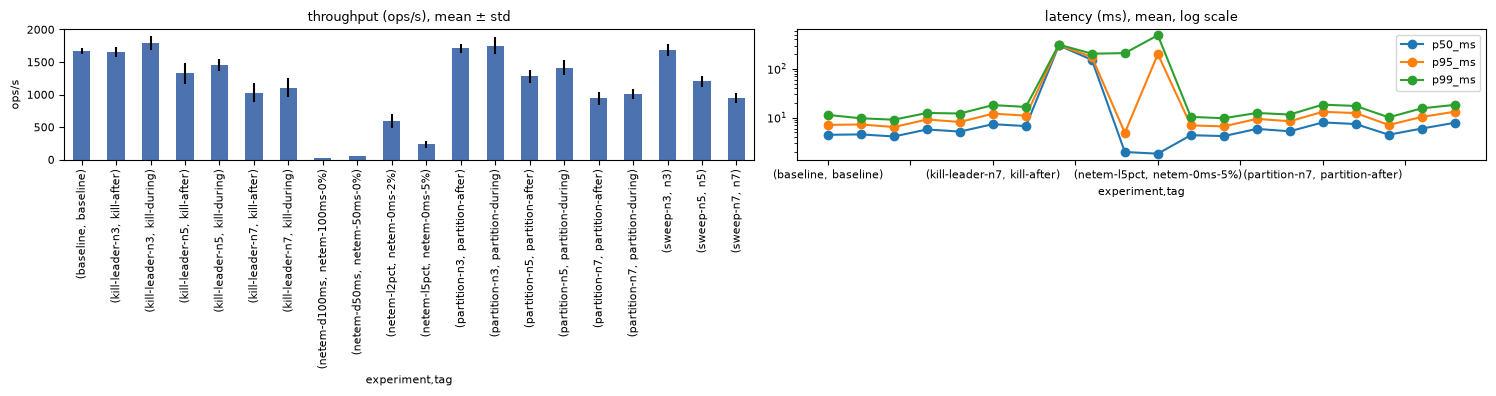

In [26]:
if not runs.empty:
    fig, axes = plt.subplots(1, 2, figsize=(15, 4))

    mean = runs.groupby(["experiment", "tag"])["throughput_ops_s"].mean()
    std = runs.groupby(["experiment", "tag"])["throughput_ops_s"].std().fillna(0)
    mean.plot.bar(yerr=std, ax=axes[0], color="#4C72B0")
    axes[0].set_title("throughput (ops/s), mean ± std")
    axes[0].set_ylabel("ops/s")

    for m in ["p50_ms", "p95_ms", "p99_ms"]:
        runs.groupby(["experiment", "tag"])[m].mean().plot(ax=axes[1], marker="o", label=m)
    axes[1].set_yscale("log")
    axes[1].set_title("latency (ms), mean, log scale")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

,seed,fault_unix_ms,time_to_elect_ms,ttr_service_ms,ttr_replica_ms,pre_term,new_term,converged,fault_cmd_ms,heal_unix_ms,experiment
0,1,1794549096428,792,2215,602,1,2,True,331,1794549099439,kill-leader-n3
1,2,1794549103522,866,2224,917,2,3,True,370,1794549106336,kill-leader-n3
2,3,1794549110784,760,745,561,3,4,True,364,1794549113525,kill-leader-n3
3,4,1794549120845,754,2250,333,4,5,True,403,1794549123670,kill-leader-n3
4,5,1794549127530,766,2281,439,5,6,True,445,1794549130222,kill-leader-n3
5,6,1794549134180,815,2224,560,6,7,True,415,1794549136928,kill-leader-n3
6,7,1794549141077,763,2197,604,7,8,True,315,1794549143903,kill-leader-n3
7,8,1794549148008,4136,5504,548,8,9,True,303,1794549154167,kill-leader-n3
8,9,1794549158455,2026,2208,675,9,11,True,328,1794549162459,kill-leader-n3
9,10,1794549166662,755,2206,603,11,12,True,336,1794549169492,kill-leader-n3


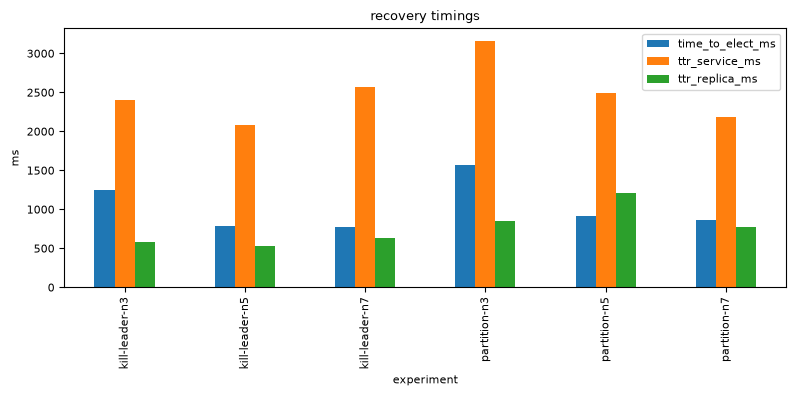

In [27]:
NUMERIC = ["time_to_elect_ms", "ttr_service_ms", "ttr_replica_ms"]

ttr_frames = []
for f in sorted(EXP.glob("*/summary.csv")):
    df = pd.read_csv(f)
    if set(NUMERIC).issubset(df.columns):
        df["experiment"] = f.parent.name
        ttr_frames.append(df)
ttr = pd.concat(ttr_frames, ignore_index=True) if ttr_frames else pd.DataFrame()

if ttr.empty:
    print("no fault runs yet (kill-leader / partition)")
else:
    for col in NUMERIC:
        ttr[col] = pd.to_numeric(ttr[col], errors="coerce")
    display(ttr)
    mean = ttr.groupby("experiment")[NUMERIC].mean()
    ax = mean.plot.bar(figsize=(8, 4))
    ax.set_ylabel("ms")
    ax.set_title("recovery timings")
    plt.tight_layout()
    plt.show()

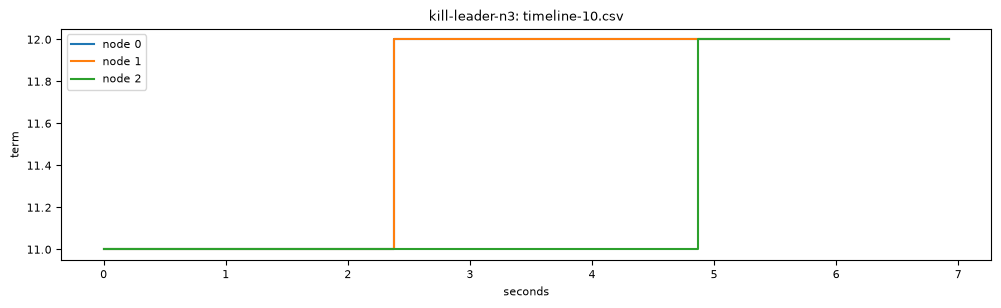

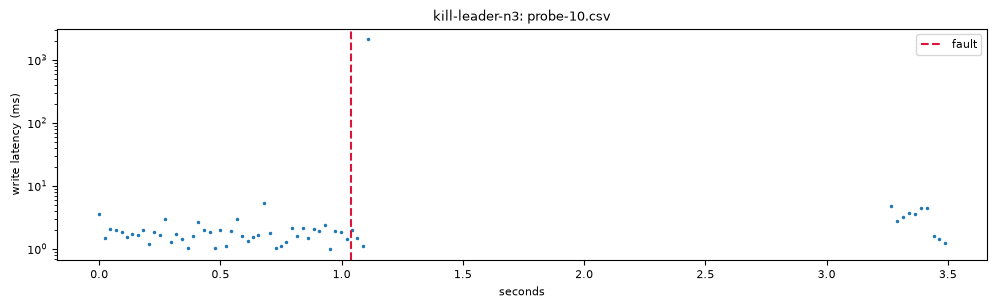

In [28]:
SCENARIO = "kill-leader-n3"   # any directory under scripts/experiments/

def latest_per_seed(prefix):
    """Newest `prefix-<seed>.csv` (fallback: `prefix.csv`), or None."""
    files = sorted((EXP / SCENARIO).glob(f"{prefix}-[0-9]*.csv"),
                   key=lambda p: int(p.stem.split("-")[1]))
    if files:
        return files[-1]
    plain = EXP / SCENARIO / f"{prefix}.csv"
    return plain if plain.exists() else None

tl_path = latest_per_seed("timeline")
if tl_path:
    tl = pd.read_csv(tl_path)
    tl["t_s"] = (tl["t_ms"] - tl["t_ms"].min()) / 1000
    fig, ax = plt.subplots(figsize=(12, 3))
    for node, g in tl.groupby("node"):
        ax.step(g["t_s"], g["term"], where="post", label=f"node {node}")
    ax.set(xlabel="seconds", ylabel="term", title=f"{SCENARIO}: {tl_path.name}")
    ax.legend()
    plt.show()

pr_path = latest_per_seed("probe")
if pr_path:
    pr = pd.read_csv(pr_path)
    pr["t_s"] = (pr["start_ns"] - pr["start_ns"].min()) / 1e9
    fig, ax = plt.subplots(figsize=(12, 3))
    ax.plot(pr["t_s"], pr["lat_ms"], ".", ms=3)

    sm_path = EXP / SCENARIO / "summary.csv"
    if sm_path.exists():
        sm = pd.read_csv(sm_path)
        seed = int(pr_path.stem.split("-")[1]) if "-" in pr_path.stem else None
        row = sm[sm["seed"] == seed] if seed is not None and "seed" in sm.columns else sm.iloc[:1]
        if not row.empty and "fault_unix_ms" in row.columns \
                and pd.notna(row["fault_unix_ms"].iloc[0]):
            fault_s = (row["fault_unix_ms"].iloc[0] * 1e6 - pr["start_ns"].min()) / 1e9
            ax.axvline(fault_s, color="crimson", ls="--", label="fault")
            ax.legend()

    ax.set_yscale("log")
    ax.set(xlabel="seconds", ylabel="write latency (ms)", title=f"{SCENARIO}: {pr_path.name}")
    plt.show()

## Como ler

* `baseline` deve ter `retry_pct ~ 0` e zero mudanças de líder; qualquer coisa
  diferente indica contenção ou timeouts agressivos.
* Em `netem`, o throughput cai e p99 sobe, mas `linearizable` continua `ok`.
* Em `kill-leader`, `time_to_elect` deve ficar perto do `ElectionTimeout`
  (500 ms + jitter) e `ttr_service` inclui o timeout HTTP do cliente (~2 s).
* `ttr_replica` cresce com o atraso do nó e com o tamanho do log; com
  `MAX_RAFT_STATE` baixo o nó atrasado é recuperado por `InstallSnapshot`.
* Term/leader no timeline mostrando `leader_id = -1` e termos crescendo sem
  parar é o problema de *disruptive server* descrito em `scripts/README.md`.


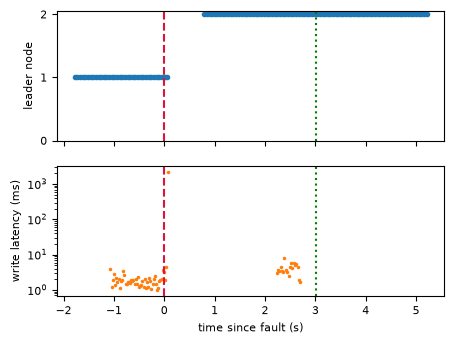

seed 1: fault at 0 s (dashed), heal at 3.0 s (dotted)


In [29]:
# Report figure: the kill-leader-n3 seed with the median time-to-elect
kill = EXP / "kill-leader-n3"
sm = pd.read_csv(kill / "summary.csv")
row = sm.sort_values("time_to_elect_ms").iloc[len(sm) // 2]
seed, fault = int(row["seed"]), row["fault_unix_ms"]
heal = (row["heal_unix_ms"] - fault) / 1000
tl = pd.read_csv(kill / f"timeline-{seed}.csv")
pr = pd.read_csv(kill / f"probe-{seed}.csv")
tl["t"] = (tl["t_ms"] - fault) / 1000
pr["t"] = (pr["start_ns"] / 1e6 - fault) / 1000
lead = tl[tl["is_leader"]]

fig, axes = plt.subplots(2, 1, figsize=(5, 3.7), sharex=True)
axes[0].plot(lead["t"], lead["node"], ".", color="C0")
axes[0].set(ylabel="leader node", yticks=sorted(tl["node"].unique()))
axes[1].plot(pr["t"], pr["lat_ms"], ".", ms=3, color="C1")
axes[1].set(yscale="log", ylabel="write latency (ms)", xlabel="time since fault (s)")
for ax in axes:
    ax.axvline(0, color="crimson", ls="--")
    ax.axvline(heal, color="green", ls=":")

figs = root / "docs" / "report" / "figs"
figs.mkdir(parents=True, exist_ok=True)
fig.savefig(figs / "kill-leader-n3.pdf", bbox_inches="tight")
plt.show()
print(f"seed {seed}: fault at 0 s (dashed), heal at {heal:.1f} s (dotted)")